# Cómo la pandemia cambió la manera de escribir de la Universidad de Sonora

Este notebook hace todo el análisis de la historia, de principio a fin:

1. **Carga** lo que descargó `scraper_unison.py`.
2. **Limpia** las noticias: quita las que no sirven, las firmas y los enlaces, y unifica los nombres de los autores.
3. **Prepara los datos de la historia:** mide cómo está escrita cada noticia y lo resume por año.
4. **Cuenta la historia:** una sección por cada parte de `post_medium.md`, con su gráfica.

**Técnicas de PLN:** limpieza y normalización de texto con expresiones regulares, tokenización, *stopwords* y
estilometría (Delta de Burrows).

**Lo que genera:**

| Archivo | Contenido |
|---|---|
| `data/noticias_limpias.csv` | Las noticias ya limpias, con sus medidas |
| `datos_historia_por_anio.csv` | La tabla por año de la que salen las gráficas |
| `graficas/` | Las gráficas del post |

## 1. Librerías

In [1]:
import os
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import nltk
from nltk.corpus import stopwords

## 2. Cargar lo que bajó el scraper

`scraper_unison.py` guarda una noticia por línea en `data/raw/noticias_unison.jsonl`.
Si el archivo no está, hay que correr el scraper en esta carpeta (el ID 18387 es de enero de 2015; tarda cerca de hora y media):

```bash
python scraper_unison.py --inicio 18387
```

In [2]:
RUTA_CRUDA = "data/raw/noticias_unison.jsonl"
if not os.path.exists(RUTA_CRUDA):
    raise FileNotFoundError("Falta el archivo del scraper: corre 'python scraper_unison.py --inicio 18387' en esta carpeta.")

crudos = pd.read_json(RUTA_CRUDA, lines=True)
print("Registros:", len(crudos))
crudos["estado"].value_counts()

Registros: 20638


estado
ok       19925
vacia      713
Name: count, dtype: int64

## 3. Limpieza

### 3.1 Quedarnos con las noticias válidas

El estado `vacia` significa que ese ID no existe en el sitio. Vamos anotando cuántas noticias quedan después de cada paso.

In [3]:
pasos = [("Registros del scraper", len(crudos))]

noticias = crudos[crudos["estado"] == "ok"].drop_duplicates(subset="id", keep="last").sort_values("id")
pasos.append(("Noticias válidas (el ID existe)", len(noticias)))

noticias["fecha"] = pd.to_datetime(noticias["fecha"])
noticias = noticias[noticias["fecha"] >= "2015-01-01"].copy()
pasos.append(("Desde enero de 2015", len(noticias)))

### 3.2 Limpiar el texto

Al revisar las notas encontramos cosas que no son parte de la noticia:

- **Firmas al inicio** que el scraper no reconoció: una primera línea de 4 palabras o menos (*Redacción*, *Paula Trespalacios Argain.*).
- **Firmas al final**, entre paréntesis: hasta 2018 las notas terminaban con las iniciales de quien las escribió (*(JAR)*, *(BE)*).
- **Enlaces y correos.**
- **Líneas sin contenido:** las que solo tienen un punto, las etiquetas que acompañaban a un enlace (*Audio:*, *Video:*)
  y las invitaciones a seguirlo (*Más información AQUÍ.*). Si se quedan, cuentan como párrafos.

In [4]:
LINEA_SIN_CONTENIDO = re.compile(r"(?i)^(\W*|(audio|video|fotos?|galer[ií]a|im[aá]gen(es)?)\s*:?\.?|.{0,50}\baqu[ií]\.?)$")


def limpiar_nota(texto):
    """Devuelve el texto limpio y las firmas que encuentre al inicio y al final."""
    lineas = [linea.strip() for linea in texto.strip().split("\n")]

    firma_inicio = None
    if len(lineas[0].split()) <= 4 and not lineas[0].endswith((",", ":")):
        firma_inicio = lineas.pop(0)
    texto = "\n".join(lineas)

    firma_final = None
    final = re.search(r"\(([^()]{1,40})\)\.?\s*$", texto)
    if final:
        firma_final = final.group(1)
        texto = texto[:final.start()]

    texto = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", texto)      # enlaces y correos
    lineas = [re.sub(r"\s+", " ", linea).strip() for linea in texto.split("\n")]
    lineas = [linea for linea in lineas if not LINEA_SIN_CONTENIDO.match(linea)]
    return "\n".join(lineas), firma_inicio, firma_final


limpias = noticias["texto"].apply(limpiar_nota)
noticias["texto_limpio"] = [resultado[0] for resultado in limpias]
noticias["firma_inicio"] = [resultado[1] for resultado in limpias]
noticias["firma_final"] = [resultado[2] for resultado in limpias]

print("Notas con firma al inicio:", noticias["firma_inicio"].notna().sum())
print("Notas con firma al final:", noticias["firma_final"].notna().sum())

Notas con firma al inicio: 474
Notas con firma al final: 7033


Un ejemplo con firma al final y un enlace:

In [5]:
ejemplo = noticias[noticias["texto"].str.contains("http") & noticias["firma_final"].notna()].iloc[0]
print("ANTES:   ...", ejemplo["texto"].strip()[-130:])
print()
print("DESPUÉS: ...", ejemplo["texto_limpio"][-90:])

ANTES:   ... de enero de 2015, a las 12:00 horas, o por internet, en la página http://www.uson.mx/medios_informativos/desdelauniversidad/. (EQ)

DESPUÉS: ... s 27 de diciembre y el 3 de enero de 2015, a las 12:00 horas, o por internet, en la página


### 3.3 Unificar las firmas

La firma es el autor que detectó el scraper o, si no hay, la que acabamos de encontrar al inicio o al final de la nota.
Un mismo nombre aparece de muchas formas (*Elías Qujada*, *Por Elías Quijada*, *Elías Quijada López*), así que buscamos
una parte distintiva de cada nombre. Si una nota tiene varias firmas, nos quedamos con la primera.

In [6]:
AUTORES = {
    "trespal|trepalac": "Paula Trespalacios Argain",
    "espinoza": "Beatriz Espinoza",
    "quijada|qujada": "Elías Quijada",
    "rubio|alberto rub": "Jesús Alberto Rubio",
    "mend[ií]vil": "Lin Mendívil Alvarado",
    "gaxiola": "Haydee Gaxiola",
    "paredes": "Olivia Paredes",
    "aleyda": "Aleyda Gutiérrez Guerrero",
    "deni[cs]+e": "Denice López Martínez",
    "mendoza": "Luis Mendoza",
    "castell[oó]n|castellanos flores": "Jonathan Castellón Flores",
    "zamora": "Armando Zamora",
    "karla": "Karla Valenzuela",
    "redacci[oó]n": "Redacción",
}
PREFIJOS = r"(?i)^\W*(por|colaboraci[oó]n( de)?|compilaci[oó]n( de)?)\b\W*"


def unificar_firma(firma):
    """Quita prefijos como 'Por', se queda con la primera firma y unifica las variantes del nombre."""
    firma = re.sub(PREFIJOS, "", firma)
    firma = re.split(r"/| y |-", firma)[0].strip(" .:()")
    for patron, nombre in AUTORES.items():
        if re.search(patron, firma, re.IGNORECASE):
            return nombre
    return firma


def parece_firma(texto):
    """Lo que va entre paréntesis al final es una firma si son iniciales o un nombre (no '(Conacyt)' ni '(2018)')."""
    texto = re.split(r"/|-", re.sub(PREFIJOS, "", texto))[0].strip()
    return bool(re.fullmatch(r"[A-ZÁÉÍÓÚÑ]{2,6}|[A-ZÁÉÍÓÚÑ]\w+( \w+){1,3}", texto))


firma_final = noticias["firma_final"].where(noticias["firma_final"].fillna("").apply(parece_firma))
sin_unificar = noticias["autor"].fillna(noticias["firma_inicio"]).fillna(firma_final)
noticias["firma"] = sin_unificar.dropna().apply(unificar_firma)

print("Firmas distintas antes:", sin_unificar.nunique(), "| después:", noticias["firma"].nunique())
print(f"Notas con firma: {noticias['firma'].notna().mean():.1%}")
noticias["firma"].value_counts().head(10)

Firmas distintas antes: 276 | después: 107
Notas con firma: 92.9%


firma
Elías Quijada                1988
Beatriz Espinoza             1945
Jesús Alberto Rubio          1920
Paula Trespalacios Argain    1875
JAR                          1816
BE                           1565
LMA                          1105
Lin Mendívil Alvarado         814
Olivia Paredes                626
Haydee Gaxiola                612
Name: count, dtype: int64

### 3.4 Quitar las notas casi vacías y las repetidas

Con el texto ya limpio volvemos a contar las palabras. Hay notas con menos de 30 palabras (avisos que solo tenían una imagen)
y algunas publicadas dos veces con el mismo texto.

In [7]:
noticias["n_palabras"] = noticias["texto_limpio"].str.split().str.len()

noticias = noticias[noticias["n_palabras"] >= 30]
pasos.append(("Con al menos 30 palabras", len(noticias)))

noticias = noticias.drop_duplicates(subset="texto_limpio", keep="first").reset_index(drop=True)
pasos.append(("Sin textos repetidos", len(noticias)))

noticias["anio"] = noticias["fecha"].dt.year
anios = sorted(noticias["anio"].unique())
pd.DataFrame(pasos, columns=["paso", "noticias"])

,paso,noticias
0,Registros del scraper,20638
1,Noticias válidas (el ID existe),19925
2,Desde enero de 2015,19925
3,Con al menos 30 palabras,19813
4,Sin textos repetidos,19786


## 4. Los datos de la historia

### 4.1 Medir cada noticia

Para cada noticia medimos cómo está escrita. Las medidas de sí o no valen 100 o 0, para que su promedio sea un porcentaje.

- **Subtítulos y párrafos:** una línea es subtítulo si tiene 7 palabras o menos y no termina en punto o coma.
- **Palabras por oración:** contamos las oraciones por los signos `. ! ?`.
- **Texto entre comillas:** qué parte de las palabras de la nota son palabras de otras personas.
- **Titular con cita:** el titular termina con quien habla (*"Unison, pionera en donación altruista de sangre: rectora"*).
  No basta con que tenga dos puntos: lo que sigue debe ser un nombre o un cargo (*"...: lo bueno y lo malo"* no cuenta).
  Solo detecta esa forma de citar; un titular puede nombrar a alguien de otra manera.

**¿Qué normalización usa cada medida?** No todas pueden usar la misma:

| Medida | Texto que usa | Por qué |
|---|---|---|
| Subtítulos, oraciones, citas y titulares | Limpio, con mayúsculas y puntuación | Esas marcas son justo lo que miden |
| Verbos y palabras funcionales | Tokens: minúsculas y solo letras | Aquí las mayúsculas y la puntuación no aportan |
| Lenguaje incluyente | Limpio, sin distinguir mayúsculas | Se busca la frase completa |

**No lematizamos** (*dijeron* → *decir*): convertiría *las y los* en *el y el*, borrando lo que queremos medir; mezclaría las formas de las
que depende la Delta de Burrows; y en los verbos sumaría usos que no son citas (*es decir*, *compartir experiencias*). En una prueba con 2,000 notas,
los verbos cambiaron en la misma dirección con y sin lemas. **Tampoco quitamos acentos:** casi no hay erratas que corregir y confundiría
palabras distintas (*sólo* y *solo*, *más* y *mas*).

In [8]:
def es_subtitulo(linea):
    return len(linea.split()) <= 7 and not linea.endswith((".", ",", ";", ":"))


lineas = noticias["texto_limpio"].str.split("\n")
noticias["n_subtitulos"] = lineas.apply(lambda notas: sum(es_subtitulo(linea) for linea in notas))
noticias["n_parrafos"] = lineas.str.len() - noticias["n_subtitulos"]
palabras_en_parrafos = lineas.apply(lambda notas: sum(len(linea.split()) for linea in notas if not es_subtitulo(linea)))
noticias["palabras_por_parrafo"] = palabras_en_parrafos / noticias["n_parrafos"].clip(lower=1)
noticias["con_subtitulo"] = (noticias["n_subtitulos"] > 0) * 100

noticias["n_oraciones"] = noticias["texto_limpio"].str.count(r"[.!?]+(\s|$)").clip(lower=1)
noticias["palabras_por_oracion"] = noticias["n_palabras"] / noticias["n_oraciones"]

citas = noticias["texto_limpio"].str.findall(r"[“\"]([^”\"]{3,})[”\"]")        # cada cita, sin las comillas
noticias["texto_en_comillas"] = citas.apply(lambda lista: sum(len(cita.split()) for cita in lista)) / noticias["n_palabras"] * 100
noticias["con_cita"] = (citas.str.len() > 0) * 100

CARGOS = ("rector|académic|especialista|investigador|expert|economista|docente|profesor|catedrátic|científic|estudiante|"
          "alumn|egresad|director|secretari|coordinador|jefe|jefa|titular|funcionari|president|gobernador|evaluador|"
          "abogad|magistrad|ponente|conferencista|sociólog|historiador|médic|psicólog|periodista|escritor|escultor|"
          "activista|consultor|analista")
NOMBRE = r"(Dr\.|Dra\.|Mtro\.|Mtra\.)?\s*[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+( (de |del |de la |la )?[A-ZÁÉÍÓÚÑ]\.?[a-záéíóúñ]*){0,4}\.?"


def titular_con_cita(titulo):
    """¿Lo que sigue a los dos puntos es quien habla (un nombre o un cargo)?"""
    if not re.search(r":\s*\S", titulo):
        return False
    despues = titulo.split(":")[-1].strip()
    if len(despues.split()) > 6:
        return False
    return bool(re.search(CARGOS, despues.lower())) or bool(re.fullmatch(NOMBRE, despues))


noticias["titular_con_cita"] = noticias["titulo"].apply(titular_con_cita) * 100
noticias["fin_de_semana"] = (noticias["fecha"].dt.day_of_week >= 5) * 100

# Lenguaje incluyente
noticias["las_y_los"] = noticias["texto_limpio"].str.contains(r"\b(?:las y los|los y las)\b", case=False) * 100
noticias["colectivos"] = noticias["texto_limpio"].str.contains("estudiantado|alumnado|profesorado", case=False) * 100
noticias["alumnos"] = noticias["texto_limpio"].str.contains(r"\balumn[oa]s?\b", case=False) * 100

# Tokenización: texto en minúsculas, solo palabras
noticias["tokens"] = noticias["texto_limpio"].str.lower().str.findall(r"[a-záéíóúüñ]+")
noticias["dijo_por_10mil"] = noticias["tokens"].apply(lambda tokens: tokens.count("dijo") + tokens.count("dijeron")) / noticias["tokens"].str.len() * 10000

COLUMNAS = ["id", "url", "fecha", "anio", "titulo", "firma", "texto_limpio", "n_palabras", "n_parrafos", "n_subtitulos",
            "palabras_por_parrafo", "palabras_por_oracion", "texto_en_comillas", "con_cita", "titular_con_cita", "dijo_por_10mil"]
noticias[COLUMNAS].to_csv("data/noticias_limpias.csv", index=False, encoding="utf-8-sig")
print("Guardadas", len(noticias), "noticias en data/noticias_limpias.csv")

Guardadas 19786 noticias en data/noticias_limpias.csv


### 4.2 La tabla por año

Una sola tabla con todo lo que usan las gráficas. Usamos la **mediana** para los tamaños (la nota típica, que no se mueve por
unas cuantas muy largas) y el **promedio** para los porcentajes. 2026 va incompleto, así que también contamos las notas de
cada año **hasta el mismo día** que la última nota.

In [9]:
ultima_fecha = noticias["fecha"].max()

por_anio = noticias.groupby("anio").agg(
    noticias=("id", "count"),
    palabras_por_noticia=("n_palabras", "median"),
    parrafos_por_noticia=("n_parrafos", "median"),
    palabras_por_parrafo=("palabras_por_parrafo", "median"),
    palabras_por_oracion=("palabras_por_oracion", "median"),
    con_subtitulo=("con_subtitulo", "mean"),
    texto_en_comillas=("texto_en_comillas", "mean"),
    con_cita=("con_cita", "mean"),
    titular_con_cita=("titular_con_cita", "mean"),
    fin_de_semana=("fin_de_semana", "mean"),
    las_y_los=("las_y_los", "mean"),
    colectivos=("colectivos", "mean"),
    alumnos=("alumnos", "mean"),
)

mismo_dia = noticias[noticias["fecha"].dt.day_of_year <= ultima_fecha.day_of_year]
por_anio["hasta_el_mismo_dia"] = mismo_dia["anio"].value_counts()

# Días con noticias y equipo (Redacción no es una persona: no cuenta como parte del equipo)
for anio, notas in noticias.groupby("anio"):
    dias = ultima_fecha.day_of_year if anio == ultima_fecha.year else (366 if anio % 4 == 0 else 365)
    por_firma = notas["firma"].value_counts().drop("Redacción", errors="ignore")
    por_anio.loc[anio, "dias_con_noticias"] = notas["fecha"].nunique() / dias * 100
    por_anio.loc[anio, "firmas_con_20_notas"] = (por_firma >= 20).sum()
    por_anio.loc[anio, "tres_principales"] = por_firma.head(3).sum() / por_firma.sum() * 100

por_anio.to_csv("datos_historia_por_anio.csv", encoding="utf-8-sig")
por_anio.round(1).T

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
noticias,2375.0,2336.0,2051.0,2053.0,1700.0,946.0,1356.0,1602.0,1650.0,1457.0,1312.0,948.0
palabras_por_noticia,370.0,381.0,374.0,382.0,435.0,517.0,587.0,536.5,478.0,469.0,444.5,435.0
parrafos_por_noticia,8.0,8.0,8.0,8.0,9.0,10.0,12.0,12.0,10.0,10.0,10.0,10.0
palabras_por_parrafo,46.4,46.1,46.6,45.5,48.7,51.4,49.5,46.4,45.1,45.0,43.4,41.1
palabras_por_oracion,42.3,42.1,42.6,41.6,44.6,45.4,44.5,43.1,42.5,42.4,38.9,39.0
con_subtitulo,2.7,6.3,11.8,13.6,17.5,22.1,33.6,70.2,95.6,94.2,65.2,38.1
texto_en_comillas,14.8,14.3,13.2,13.3,15.5,17.4,20.7,24.6,22.3,25.5,22.5,16.2
con_cita,86.7,80.1,70.3,69.8,76.9,79.2,86.4,92.6,87.9,89.6,88.5,78.2
titular_con_cita,7.0,8.9,9.3,7.2,10.2,10.8,14.5,11.6,9.9,10.2,7.4,2.5
fin_de_semana,2.0,5.4,5.1,5.4,3.5,7.1,7.5,2.6,4.5,3.6,2.5,0.9


## 5. El estilo de las gráficas

Estas funciones solo dan formato, para que todas las gráficas se vean igual. La pandemia y la nueva rectoría van sombreadas en gris.

In [10]:
os.makedirs("graficas", exist_ok=True)
FUENTE = f"Fuente: {len(noticias):,} noticias de unison.mx, enero de 2015 a octubre de 2026."

FONDO, TINTA, TINTA_2, TENUE, REJILLA, BASE, BANDA = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f0efec"
AZUL, NARANJA, VERDE, AZUL_CLARO = "#2a78d6", "#eb6834", "#1baf7a", "#86b6ef"

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 12, "axes.edgecolor": BASE, "xtick.color": TENUE, "ytick.color": TENUE,
    "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2, "figure.facecolor": FONDO, "axes.facecolor": FONDO, "lines.linewidth": 2,
})


def nueva_figura(titulo, subtitulo, ancho=11, alto=5.6, columnas=1, izquierda=0.07, arriba=1.25):
    """Figura con título y subtítulo arriba a la izquierda."""
    fig, ejes = plt.subplots(1, columnas, figsize=(ancho, alto))
    fig.subplots_adjust(top=1 - arriba / alto, bottom=0.75 / alto, left=izquierda, right=0.96, wspace=0.25)
    fig.text(0.07, 1 - 0.25 / alto, titulo, fontsize=17, fontweight="bold", color=TINTA, va="top")
    fig.text(0.07, 1 - 0.65 / alto, subtitulo, fontsize=12, color=TINTA_2, va="top")
    return fig, ejes


def formato(eje, rejilla="y", porcentaje=False):
    """Deja solo la línea de base y una rejilla suave."""
    for lado in ["top", "right", "left"]:
        eje.spines[lado].set_visible(False)
    eje.tick_params(length=0)
    eje.grid(axis=rejilla, color=REJILLA, linewidth=1)
    eje.set_axisbelow(True)
    if porcentaje:
        eje.yaxis.set_major_formatter(lambda valor, _: f"{valor:.0f}%")


def bandas(eje):
    """Sombrea la pandemia y la nueva rectoría en una gráfica por año."""
    arriba = eje.get_ylim()[1]
    for inicio, fin, nombre in [(2019.5, 2021.5, "Pandemia"), (2024.5, 2026.5, "Nueva rectoría")]:
        eje.axvspan(inicio, fin, color=BANDA, zorder=0)
        eje.text((inicio + fin) / 2, arriba, nombre, ha="center", va="bottom", fontsize=10, color=TINTA_2)


def etiqueta(eje, x, y, texto, dx=0, dy=9, ha="center"):
    eje.annotate(texto, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=11, color=TINTA)


def lineas_con_valor_final(eje, series, marcador="o"):
    """Dibuja cada (serie, nombre, color) y escribe su último valor junto a la línea."""
    for serie, nombre, color in series:
        eje.plot(serie.index, serie.values, color=color, marker=marcador, markersize=7, label=nombre, zorder=3)
        etiqueta(eje, serie.index[-1], serie.iloc[-1], f"{serie.iloc[-1]:.0f}%", dx=10, dy=-5, ha="left")


def guardar(fig, nombre, nota=""):
    """Agrega la fuente, guarda la gráfica en graficas/ y la muestra."""
    fig.text(0.07, 0.2 / fig.get_figheight(), (nota + "  " if nota else "") + FUENTE, fontsize=9, color=TENUE)
    fig.savefig(os.path.join("graficas", nombre), dpi=200, facecolor=FONDO)
    plt.show()

## 6. La historia

### 6.1 Menos noticias, de golpe

A la misma fecha: 2020 contra 2019, -48%; 2026 contra 2025, -14%


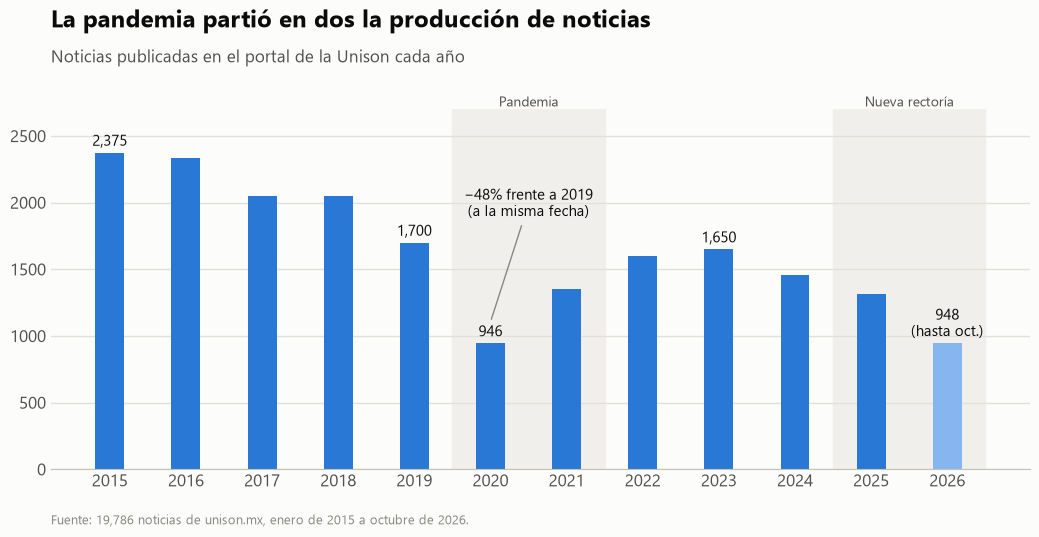

In [11]:
caida_2020 = (por_anio.loc[2020, "hasta_el_mismo_dia"] / por_anio.loc[2019, "hasta_el_mismo_dia"] - 1) * 100
caida_2026 = (por_anio.loc[2026, "hasta_el_mismo_dia"] / por_anio.loc[2025, "hasta_el_mismo_dia"] - 1) * 100
print(f"A la misma fecha: 2020 contra 2019, {caida_2020:.0f}%; 2026 contra 2025, {caida_2026:.0f}%")

fig, eje = nueva_figura("La pandemia partió en dos la producción de noticias", "Noticias publicadas en el portal de la Unison cada año")
colores = [AZUL_CLARO if anio == ultima_fecha.year else AZUL for anio in anios]     # 2026, incompleto, más claro
eje.bar(por_anio.index, por_anio["noticias"], width=0.38, color=colores, zorder=2)
formato(eje)
eje.set_ylim(0, 2700)
eje.set_xticks(anios)
bandas(eje)
for anio in [2015, 2019, 2020, 2023]:
    etiqueta(eje, anio, por_anio.loc[anio, "noticias"], f"{por_anio.loc[anio, 'noticias']:,}", dy=5)
etiqueta(eje, 2026, por_anio.loc[2026, "noticias"], f"{por_anio.loc[2026, 'noticias']:,}\n(hasta oct.)", dy=5)
eje.annotate(f"{caida_2020:.0f}% frente a 2019\n(a la misma fecha)".replace("-", "−"), (2020, por_anio.loc[2020, "noticias"] + 160),
             xytext=(2020.5, 1900), ha="center", fontsize=11, color=TINTA, arrowprops={"arrowstyle": "-", "color": TENUE, "linewidth": 1})
guardar(fig, "01_noticias_por_anio.png")

### 6.2 Notas más largas y, por un tiempo, con subtítulos

Las notas crecen con la pandemia. Y aparece un formato nuevo: casi todas las notas llevan subtítulos entre 2023 y 2024.
El cambio no es gradual: mes por mes, empieza en agosto de 2022 y termina a mediados de 2025.

In [12]:
por_periodo = {
    "ene–jul 2022": noticias["fecha"].between("2022-01-01", "2022-07-31"),
    "ago 2022–abr 2025": noticias["fecha"].between("2022-08-01", "2025-04-30"),
    "ago 2025–oct 2026": noticias["fecha"] >= "2025-08-01",
}
subtitulos_por_periodo = pd.Series({periodo: noticias.loc[filtro, "con_subtitulo"].mean() for periodo, filtro in por_periodo.items()})
subtitulos_por_periodo.round(0)

ene–jul 2022         51.0
ago 2022–abr 2025    94.0
ago 2025–oct 2026    41.0
dtype: float64

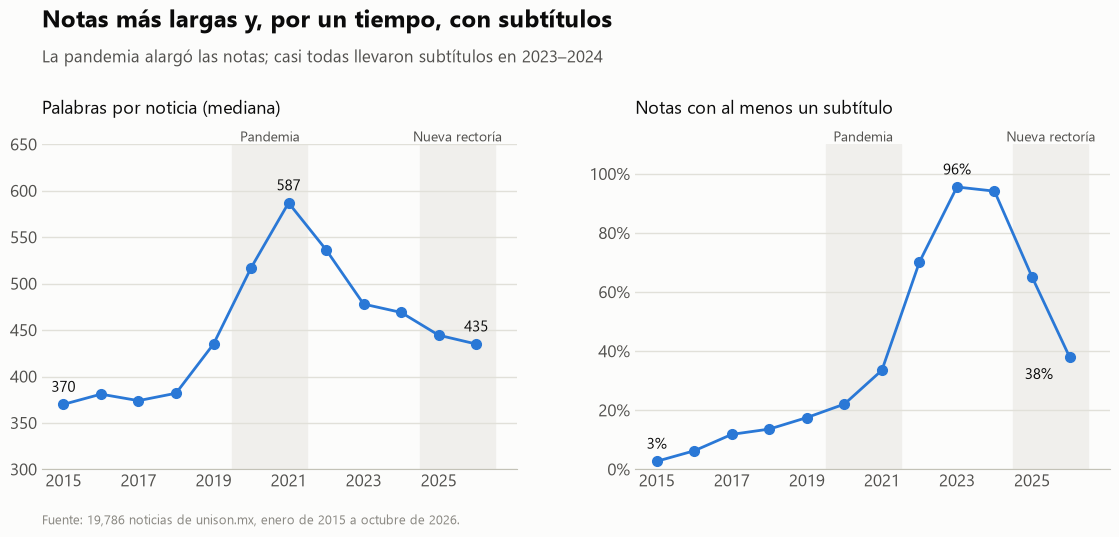

In [13]:
fig, (izquierda, derecha) = nueva_figura("Notas más largas y, por un tiempo, con subtítulos",
                                         "La pandemia alargó las notas; casi todas llevaron subtítulos en 2023–2024",
                                         ancho=12, columnas=2, arriba=1.6)

palabras = por_anio["palabras_por_noticia"]
izquierda.plot(palabras.index, palabras.values, color=AZUL, marker="o", markersize=7, zorder=3)
izquierda.set_ylim(300, 650)
izquierda.set_title("Palabras por noticia (mediana)", loc="left", fontsize=13, color=TINTA, pad=22)
formato(izquierda)
for anio in [2015, palabras.idxmax(), 2026]:
    etiqueta(izquierda, anio, palabras[anio], f"{palabras[anio]:.0f}")

subtitulos = por_anio["con_subtitulo"]
derecha.plot(subtitulos.index, subtitulos.values, color=AZUL, marker="o", markersize=7, zorder=3)
derecha.set_ylim(0, 110)
derecha.set_title("Notas con al menos un subtítulo", loc="left", fontsize=13, color=TINTA, pad=22)
formato(derecha, porcentaje=True)
for anio in [2015, subtitulos.idxmax()]:
    etiqueta(derecha, anio, subtitulos[anio], f"{subtitulos[anio]:.0f}%")
etiqueta(derecha, 2026, subtitulos[2026], f"{subtitulos[2026]:.0f}%", dx=-12, dy=-16, ha="right")

for eje in [izquierda, derecha]:
    eje.set_xticks(anios[::2])
    bandas(eje)
guardar(fig, "02_largo_y_subtitulos.png")

### 6.3 La pandemia llenó las notas de voces

Por *voces* entendemos las palabras de otras personas que una nota reproduce tal cual, entre comillas o en el titular.

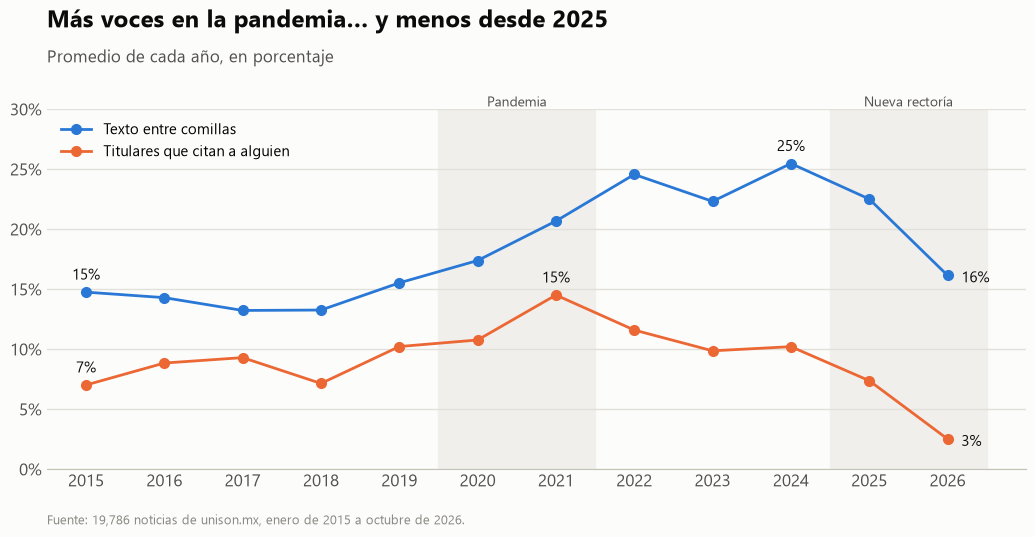

In [14]:
fig, eje = nueva_figura("Más voces en la pandemia… y menos desde 2025", "Promedio de cada año, en porcentaje")
comillas, titulares = por_anio["texto_en_comillas"], por_anio["titular_con_cita"]
lineas_con_valor_final(eje, [(comillas, "Texto entre comillas", AZUL), (titulares, "Titulares que citan a alguien", NARANJA)])
for serie in [comillas, titulares]:
    etiqueta(eje, 2015, serie[2015], f"{serie[2015]:.0f}%")
    etiqueta(eje, serie.idxmax(), serie.max(), f"{serie.max():.0f}%")
formato(eje, porcentaje=True)
eje.set_ylim(0, 30)
eje.set_xlim(2014.5, 2027)
eje.set_xticks(anios)
bandas(eje)
eje.legend(loc="upper left", frameon=False, fontsize=11)
guardar(fig, "03_voces.png")

### 6.4 2025: las voces se apagan

El 16 de junio de 2025 asumió la nueva rectora (según el propio portal: *"Asume Dena María Camarena Gómez la Rectoría de la
Universidad de Sonora"*). Comparamos los meses de antes y de después, sin junio y julio, y vemos el cambio mes por mes.
En la gráfica usamos un **promedio móvil de 3 meses**, porque algunos meses tienen muy pocas notas.

In [15]:
MEDIDAS_DEL_CAMBIO = ["texto_en_comillas", "titular_con_cita", "con_subtitulo", "dijo_por_10mil"]

antes_del_cambio = noticias[noticias["fecha"].between("2024-01-01", "2025-05-31")][MEDIDAS_DEL_CAMBIO].mean()
despues_del_cambio = noticias[noticias["fecha"] >= "2025-08-01"][MEDIDAS_DEL_CAMBIO].mean()
pd.DataFrame({"ene 2024 – may 2025": antes_del_cambio, "ago 2025 – oct 2026": despues_del_cambio}).round(1)

,ene 2024 – may 2025,ago 2025 – oct 2026
texto_en_comillas,24.9,17.7
titular_con_cita,10.8,2.1
con_subtitulo,90.9,40.5
dijo_por_10mil,12.4,6.6


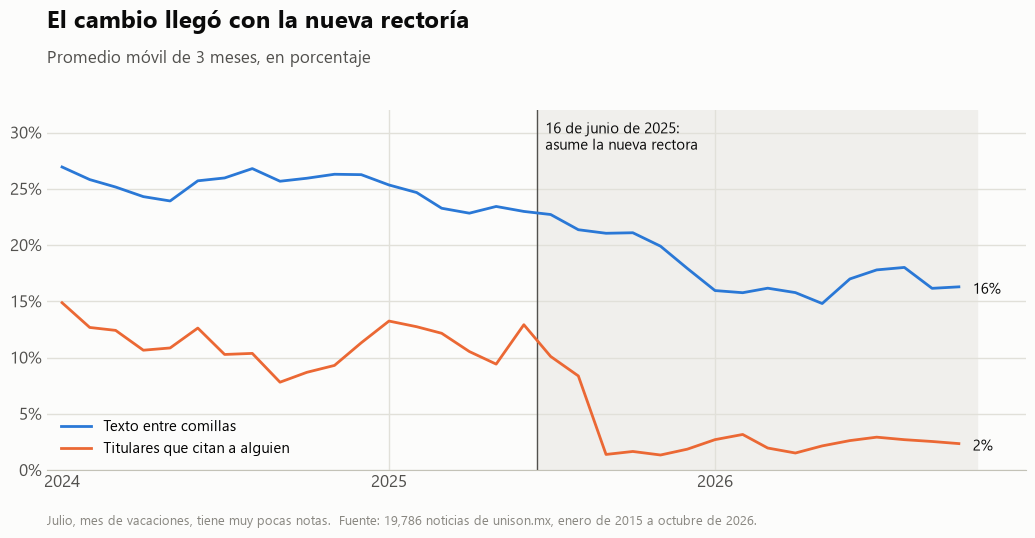

In [16]:
recientes = noticias[noticias["fecha"] >= "2024-01-01"]
por_mes = recientes.groupby(recientes["fecha"].dt.to_period("M").dt.to_timestamp())[["texto_en_comillas", "titular_con_cita"]].mean()
suavizado = por_mes.rolling(3, center=True, min_periods=2).mean()
cambio_de_rectoria = pd.Timestamp("2025-06-16")

fig, eje = nueva_figura("El cambio llegó con la nueva rectoría", "Promedio móvil de 3 meses, en porcentaje")
eje.axvspan(cambio_de_rectoria, por_mes.index.max() + pd.Timedelta(days=20), color=BANDA, zorder=0)
lineas_con_valor_final(eje, [(suavizado["texto_en_comillas"], "Texto entre comillas", AZUL),
                             (suavizado["titular_con_cita"], "Titulares que citan a alguien", NARANJA)], marcador=None)
eje.axvline(cambio_de_rectoria, color=TINTA_2, linewidth=1)
eje.text(cambio_de_rectoria, 31, "  16 de junio de 2025:\n  asume la nueva rectora", fontsize=11, color=TINTA, va="top")
formato(eje, porcentaje=True)
eje.set_ylim(0, 32)
eje.set_xlim(pd.Timestamp("2023-12-15"), pd.Timestamp("2026-12-15"))

# Eje x: solo los años, cada uno donde empieza, con una línea tenue
inicios_de_anio = pd.to_datetime(["2024-01-01", "2025-01-01", "2026-01-01"])
eje.set_xticks(inicios_de_anio, ["2024", "2025", "2026"])
for inicio in inicios_de_anio[1:]:
    eje.axvline(inicio, color=REJILLA, linewidth=1, zorder=0)

eje.legend(loc="lower left", frameon=False, fontsize=11)
guardar(fig, "05_mes_a_mes.png", nota="Julio, mes de vacaciones, tiene muy pocas notas.")

**Los verbos con que se cita.** *Dijo* solo informa; *destacó* o *compartió* ya valoran lo que se dice (esta lectura es nuestra, no una medida).
Contamos 25 verbos de cita en pasado, en singular y plural (*dijo* y *dijeron*), por cada 10,000 palabras, y graficamos los seis que más suben y los seis que más bajan.

In [17]:
VERBOS = {
    "dijo": "dijeron", "señaló": "señalaron", "indicó": "indicaron", "destacó": "destacaron", "añadió": "añadieron",
    "expresó": "expresaron", "comentó": "comentaron", "mencionó": "mencionaron", "informó": "informaron", "explicó": "explicaron",
    "agregó": "agregaron", "resaltó": "resaltaron", "apuntó": "apuntaron", "afirmó": "afirmaron", "precisó": "precisaron",
    "subrayó": "subrayaron", "consideró": "consideraron", "advirtió": "advirtieron", "sostuvo": "sostuvieron",
    "puntualizó": "puntualizaron", "reconoció": "reconocieron", "aseguró": "aseguraron", "compartió": "compartieron",
    "detalló": "detallaron", "enfatizó": "enfatizaron",
}


def verbos_por_10mil(notas):
    """Usos de cada verbo (singular + plural) por cada 10,000 palabras."""
    conteo = Counter()
    for tokens in notas["tokens"]:
        conteo.update(tokens)
    total = sum(conteo.values())
    return pd.Series({singular: (conteo[singular] + conteo[plural]) / total * 10000 for singular, plural in VERBOS.items()})


verbos = pd.DataFrame({
    "2015–2019": verbos_por_10mil(noticias[noticias["anio"] <= 2019]),
    "2025–2026": verbos_por_10mil(noticias[noticias["anio"] >= 2025]),
})
verbos["cambio"] = verbos["2025–2026"] - verbos["2015–2019"]
verbos = verbos.sort_values("cambio")
verbos.round(1)

,2015–2019,2025–2026,cambio
dijo,17.3,8.5,-8.8
indicó,9.0,5.3,-3.7
añadió,7.8,5.8,-2.0
mencionó,4.8,2.8,-2.0
apuntó,2.9,1.0,-1.8
afirmó,3.1,1.4,-1.8
comentó,6.6,4.9,-1.7
sostuvo,2.2,0.7,-1.5
informó,4.9,3.5,-1.4
advirtió,2.3,1.3,-1.0


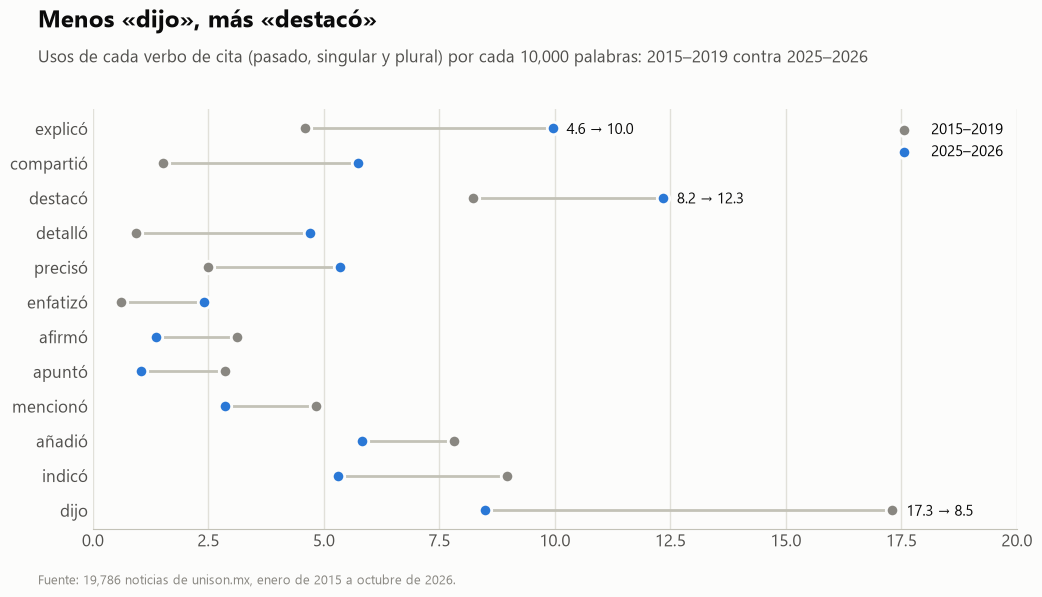

In [18]:
elegidos = pd.concat([verbos.head(6), verbos.tail(6)])
antes, despues = elegidos["2015–2019"], elegidos["2025–2026"]
filas = range(len(elegidos))

fig, eje = nueva_figura("Menos «dijo», más «destacó»", "Usos de cada verbo de cita (pasado, singular y plural) por cada 10,000 palabras: 2015–2019 contra 2025–2026",
                        alto=6.2, izquierda=0.12)
eje.hlines(filas, antes, despues, color=BASE, linewidth=2, zorder=1)
eje.scatter(antes, filas, s=80, color=TENUE, edgecolor=FONDO, linewidth=2, zorder=2, label="2015–2019")
eje.scatter(despues, filas, s=80, color=AZUL, edgecolor=FONDO, linewidth=2, zorder=3, label="2025–2026")
eje.set_yticks(filas, elegidos.index)
formato(eje, rejilla="x")
eje.set_xlim(0, 20)
for verbo in ["dijo", "destacó", "explicó"]:
    etiqueta(eje, max(antes[verbo], despues[verbo]), list(elegidos.index).index(verbo),
             f"{antes[verbo]:.1f} → {despues[verbo]:.1f}", dx=10, dy=-4, ha="left")
eje.legend(loc="upper right", frameon=False, fontsize=11)
guardar(fig, "04_verbos.png")

### 6.5 No cambió el equipo: cambió la línea editorial

¿Llegaron periodistas nuevos o las mismas personas escriben distinto? Tomamos las tres firmas con más notas desde 2024 y comparamos
a cada una **consigo misma** (solo años con al menos 30 notas suyas). En el post no usamos sus nombres: lo que importa es que son las
mismas personas.

In [19]:
principales = noticias[noticias["anio"] >= 2024]["firma"].value_counts().drop("Redacción", errors="ignore").head(3).index
periodistas = dict(zip(principales, ["Periodista A", "Periodista B", "Periodista C"]))

de_principales = noticias[noticias["firma"].isin(principales)].copy()
de_principales["periodista"] = de_principales["firma"].map(periodistas)
por_periodista = de_principales.groupby(["periodista", "anio"]).agg(
    notas=("id", "count"),
    texto_en_comillas=("texto_en_comillas", "mean"),
    titular_con_cita=("titular_con_cita", "mean"),
    con_subtitulo=("con_subtitulo", "mean"),
    dijo_por_10mil=("dijo_por_10mil", "mean"),
)
por_periodista = por_periodista[por_periodista["notas"] >= 30]

print(f"Las tres escriben {por_anio.loc[2026, 'tres_principales']:.0f}% de las notas firmadas de 2026")
por_periodista.loc[(slice(None), [2024, 2026]), :].round(1)

Las tres escriben 78% de las notas firmadas de 2026


notas  texto_en_comillas  titular_con_cita  con_subtitulo  \
periodista   anio                                                              
Periodista A 2024    426               34.3               6.6           97.2   
             2026    237               25.1               0.8           48.1   
Periodista B 2024    392               20.6              11.0           93.9   
             2026    240               11.9               3.3           48.8   
Periodista C 2024    282               18.0              18.4           95.0   
             2026    174                8.6               4.0           25.3   

                   dijo_por_10mil  
periodista   anio                  
Periodista A 2024             9.2  
             2026             4.1  
Periodista B 2024            22.1  
             2026             9.2  
Periodista C 2024            13.6  
             2026             5.7

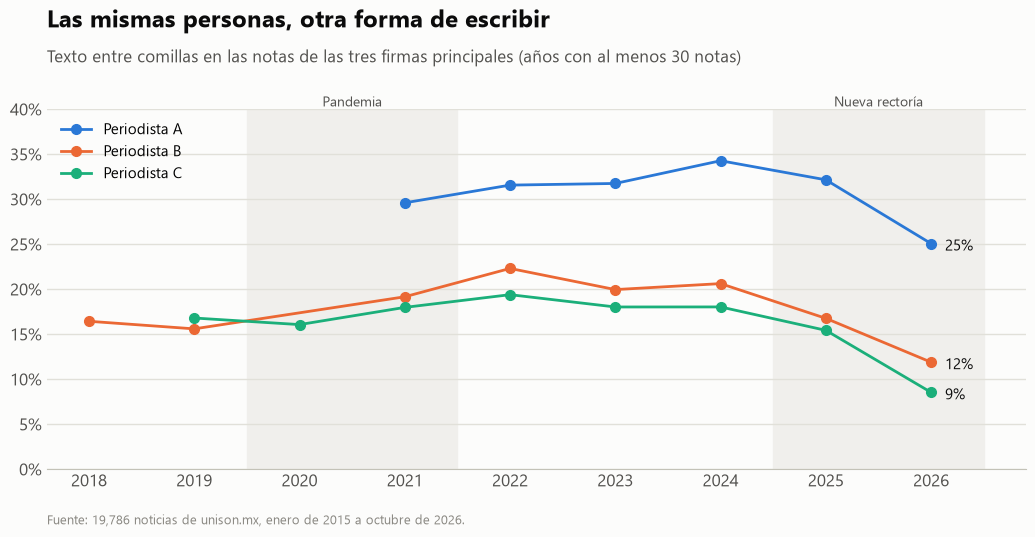

In [20]:
fig, eje = nueva_figura("Las mismas personas, otra forma de escribir",
                        "Texto entre comillas en las notas de las tres firmas principales (años con al menos 30 notas)")
series = [(por_periodista.loc[nombre, "texto_en_comillas"], nombre, color)
          for nombre, color in zip(["Periodista A", "Periodista B", "Periodista C"], [AZUL, NARANJA, VERDE])]
lineas_con_valor_final(eje, series)
formato(eje, porcentaje=True)
eje.set_ylim(0, 40)
eje.set_xlim(2017.6, 2026.9)
eje.set_xticks(range(2018, 2027))
bandas(eje)
eje.legend(loc="upper left", frameon=False, fontsize=11)
guardar(fig, "06_reporteros.png")

### 6.6 La huella en las palabras pequeñas

Para analizar temas se quitan las *stopwords* (*de, la, que, los...*). Para analizar el **estilo** son justo lo que importa: casi nadie
decide a propósito cuántas veces escribe *los* o *con*, y esas costumbres forman una especie de huella. El método clásico para medirla
es la **Delta de Burrows** (John Burrows, 2002). Se creó para identificar autores; aquí lo usamos para comparar años.

**La idea:** dos textos tienen un estilo parecido si se alejan de lo normal de la misma manera, con las mismas palabras.

**Los pasos:**

1. **Elegir las palabras:** las 60 *stopwords* más frecuentes de todas las noticias. Burrows usa las palabras más frecuentes sin filtrar;
   aquí dejamos solo las *stopwords* para que no pesen palabras de tema como *universidad* o *sonora*. Más abajo comprobamos si eso cambia el resultado.
2. **Contarlas:** para cada año, cuántas veces aparece cada una por cada 1,000 palabras. Así no importa que unos años tengan más notas.
3. **Ponerlas en la misma escala:** *en* aparece unas 31 veces por cada 1,000 palabras y *quienes* menos de una, así que no se pueden
   comparar directamente. Usamos el **puntaje z**: cuánto se aleja cada año del promedio de esa palabra, medido en desviaciones estándar.
   0 es lo normal, +2 es mucho más que lo normal y −2 es mucho menos.
4. **Comparar dos años:** para cada palabra restamos sus dos puntajes y quitamos el signo. El promedio de esas 60 diferencias es la **Delta**.
   Cerca de 0 significa el mismo estilo; entre más grande, más distinto.

La Delta no es un porcentaje ni tiene un valor que separe "parecido" de "distinto": sirve para comparar los años entre sí, dentro de estas noticias.

In [21]:
nltk.download("stopwords", quiet=True)
stopwords_es = set(stopwords.words("spanish"))

conteo_por_anio = {}
for anio, notas in noticias.groupby("anio"):
    conteo_por_anio[anio] = Counter(token for tokens in notas["tokens"] for token in tokens)
conteo_total = sum(conteo_por_anio.values(), Counter())


def calcular_delta(palabras):
    """Frecuencias por año, puntajes z y distancia entre años para una lista de palabras."""
    frecuencias = pd.DataFrame({anio: {palabra: conteo[palabra] / sum(conteo.values()) * 1000 for palabra in palabras}
                                for anio, conteo in conteo_por_anio.items()})       # filas: palabras, columnas: años
    puntajes_z = frecuencias.sub(frecuencias.mean(axis=1), axis=0).div(frecuencias.std(axis=1), axis=0)
    delta = pd.DataFrame({a: {b: (puntajes_z[a] - puntajes_z[b]).abs().mean() for b in anios} for a in anios})
    return frecuencias, puntajes_z, delta


palabras_comunes = [palabra for palabra, veces in conteo_total.most_common()]
funcionales = [palabra for palabra in palabras_comunes if palabra in stopwords_es][:60]
frecuencias, puntajes_z, delta = calcular_delta(funcionales)
delta.round(2)

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
2015,0.00,0.39,0.47,0.62,0.76,1.00,1.06,1.30,1.06,1.38,1.01,1.78
2016,0.39,0.00,0.43,0.61,0.67,0.84,0.96,1.16,0.92,1.31,1.04,1.89
2017,0.47,0.43,0.00,0.37,0.62,0.89,1.00,1.20,0.96,1.35,1.03,1.83
2018,0.62,0.61,0.37,0.00,0.60,0.92,1.09,1.35,1.12,1.52,1.18,1.88
2019,0.76,0.67,0.62,0.60,0.00,0.69,0.91,1.15,0.96,1.35,1.07,1.94
2020,1.00,0.84,0.89,0.92,0.69,0.00,0.54,0.93,0.90,1.23,1.00,1.99
2021,1.06,0.96,1.00,1.09,0.91,0.54,0.00,0.74,0.79,1.13,1.02,2.08
2022,1.30,1.16,1.20,1.35,1.15,0.93,0.74,0.00,0.58,0.73,1.16,2.48
2023,1.06,0.92,0.96,1.12,0.96,0.90,0.79,0.58,0.00,0.72,1.02,2.32
2024,1.38,1.31,1.35,1.52,1.35,1.23,1.13,0.73,0.72,0.00,1.09,2.53


**Un ejemplo con tres palabras.** Comparamos 2015 con 2016 (años vecinos) y con 2026. Primero, cuántas veces aparece cada palabra por cada
1,000 palabras; después, sus puntajes z y la diferencia entre años. Entre 2015 y 2016 las diferencias son pequeñas; con 2026 son grandes.

In [22]:
palabras_ejemplo = ["los", "quienes", "con"]
anios_ejemplo = [2015, 2016, 2026]

print("Veces por cada 1,000 palabras:")
print(frecuencias.loc[palabras_ejemplo, anios_ejemplo].round(2))

ejemplo = puntajes_z.loc[palabras_ejemplo, anios_ejemplo].copy()
ejemplo["diferencia 2015 y 2016"] = (ejemplo[2015] - ejemplo[2016]).abs()
ejemplo["diferencia 2015 y 2026"] = (ejemplo[2015] - ejemplo[2026]).abs()

print()
print("Puntajes z y diferencias:")
print(ejemplo.round(1))

print()
print("Delta con estas 3 palabras:", ejemplo["diferencia 2015 y 2016"].mean().round(2), "y", ejemplo["diferencia 2015 y 2026"].mean().round(2))
print("Delta con las 60 palabras:", delta.loc[2015, 2016].round(2), "y", delta.loc[2015, 2026].round(2))

Veces por cada 1,000 palabras:
          2015   2016   2026
los      16.49  16.60  13.13
quienes   0.84   0.77   1.37
con       9.99   9.46  11.93

Puntajes z y diferencias:
         2015  2016  2026  diferencia 2015 y 2016  diferencia 2015 y 2026
los       1.0   1.1  -2.5                     0.1                     3.5
quienes   0.0  -0.3   2.7                     0.3                     2.7
con      -0.1  -0.9   2.9                     0.8                     3.0

Delta con estas 3 palabras: 0.42 y 3.06
Delta con las 60 palabras: 0.39 y 1.78


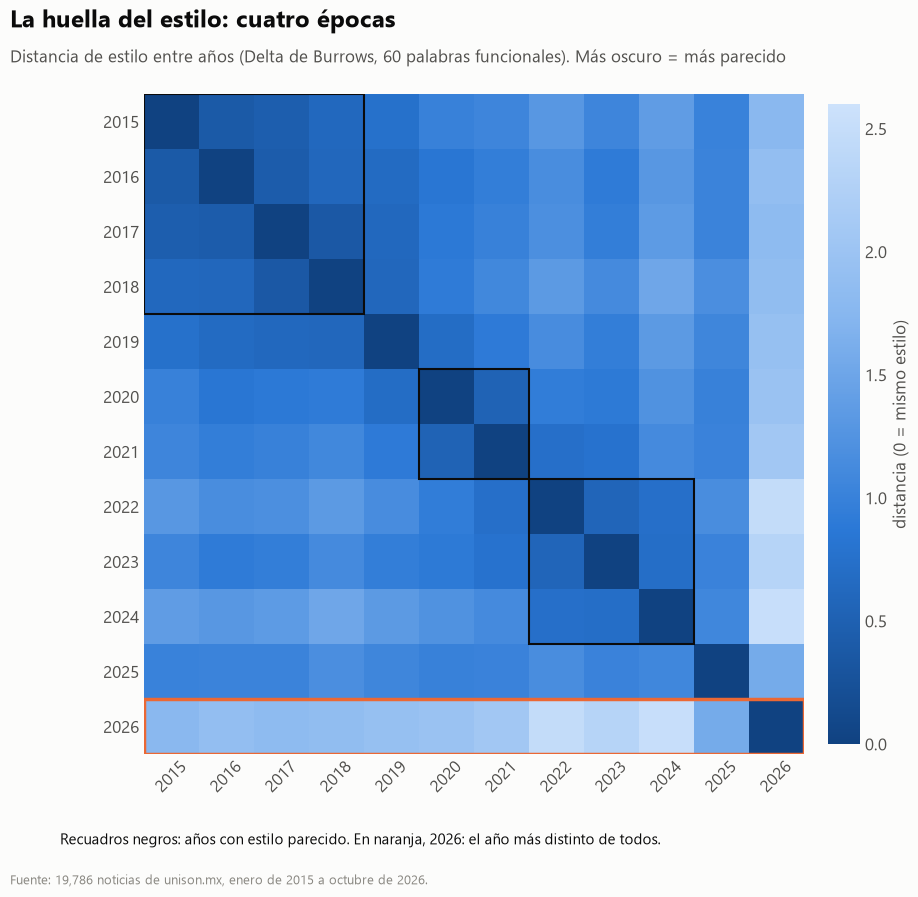

In [23]:
mapa = LinearSegmentedColormap.from_list("azules", ["#104281", "#2a78d6", "#86b6ef", "#cde2fb"])       # oscuro = parecido

fig, eje = nueva_figura("La huella del estilo: cuatro épocas",
                        "Distancia de estilo entre años (Delta de Burrows, 60 palabras funcionales). Más oscuro = más parecido",
                        ancho=10, alto=9.2)
fig.subplots_adjust(top=1 - 1.1 / 9.2, bottom=1.5 / 9.2, left=0.12, right=0.92)
imagen = eje.imshow(delta.values, cmap=mapa, vmin=0, vmax=2.6)
eje.set_xticks(range(len(anios)), anios, rotation=45)
eje.set_yticks(range(len(anios)), anios)
eje.tick_params(length=0)
for lado in eje.spines.values():
    lado.set_visible(False)

for inicio, fin in [(2015, 2018), (2020, 2021), (2022, 2024)]:             # bloques de años parecidos
    i, j = anios.index(inicio), anios.index(fin)
    eje.add_patch(Rectangle((i - 0.5, i - 0.5), j - i + 1, j - i + 1, fill=False, edgecolor=TINTA, linewidth=1.5))
eje.add_patch(Rectangle((-0.5, anios.index(2026) - 0.5), len(anios), 1, fill=False, edgecolor=NARANJA, linewidth=2.5))
fig.text(0.12, 0.6 / 9.2, "Recuadros negros: años con estilo parecido. En naranja, 2026: el año más distinto de todos.", fontsize=11, color=TINTA)

barra = fig.colorbar(imagen, ax=eje, fraction=0.04, pad=0.03)
barra.outline.set_visible(False)
barra.ax.tick_params(length=0)
barra.set_label("distancia (0 = mismo estilo)", color=TINTA_2)
guardar(fig, "07_huella_de_estilo.png")

**¿Importa haber elegido solo *stopwords*?** Repetimos el cálculo con la lista de Burrows (las 150 palabras más frecuentes, sin filtrar)
y con 150 palabras de tema (sin *stopwords*).

In [24]:
def comparar_con_la_nuestra(nombre, palabras):
    otra = calcular_delta(palabras)[2]
    pares = [(a, b) for a in anios for b in anios if a < b]
    nuestra_serie = pd.Series([delta.loc[par] for par in pares])
    otra_serie = pd.Series([otra.loc[par] for par in pares])
    return {
        "lista": nombre,
        "correlación con la nuestra": round(nuestra_serie.corr(otra_serie), 2),
        "2015–2016": round(otra.loc[2015, 2016], 2),
        "2015–2026": round(otra.loc[2015, 2026], 2),
        "año más distinto": otra.mean().idxmax(),
    }


pd.DataFrame([
    comparar_con_la_nuestra("60 stopwords (la nuestra)", funcionales),
    comparar_con_la_nuestra("150 más frecuentes, sin filtrar", palabras_comunes[:150]),
    comparar_con_la_nuestra("150 de tema, sin stopwords", [p for p in palabras_comunes if p not in stopwords_es][:150]),
])

,lista,correlación con la nuestra,2015–2016,2015–2026,año más distinto
0,60 stopwords (la nuestra),1.00,0.39,1.78,2026
1,"150 más frecuentes, sin filtrar",0.98,0.39,1.83,2026
2,"150 de tema, sin stopwords",0.91,0.46,1.87,2026


El resultado casi no depende de la lista. Pero las palabras de tema agrupan los años de forma parecida, así que la Delta **no prueba por sí sola**
que el estilo cambiara aparte de los temas: sirve como apoyo. La evidencia más directa son las citas, los subtítulos y los verbos, medidos en las mismas personas.

¿Qué palabras pequeñas cambiaron más entre 2015–2019 y 2025–2026? (diferencia de puntajes z)

In [25]:
cambio_funcionales = (puntajes_z[[2025, 2026]].mean(axis=1) - puntajes_z[[2015, 2016, 2017, 2018, 2019]].mean(axis=1)).sort_values()
print("Se usan menos:", ", ".join(cambio_funcionales.head(8).index))
print("Se usan más:  ", ", ".join(cambio_funcionales.tail(8).index[::-1]))

Se usan menos: esa, otras, le, los, ese, en, otros, cual
Se usan más:   como, con, una, durante, quienes, desde, su, también


*Quienes* sube y *los* baja: la huella de una forma de escribir que evita el masculino genérico. Lo medimos directamente:

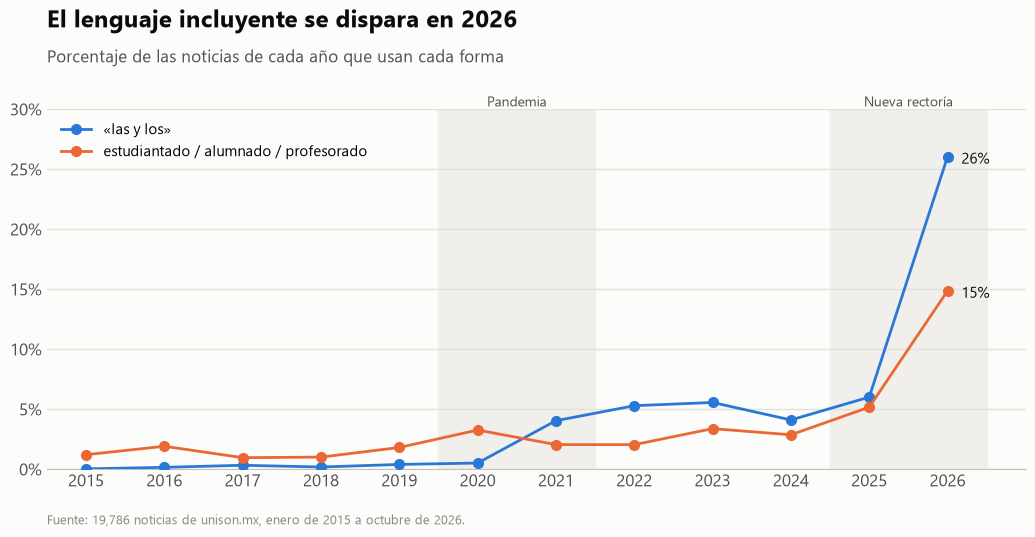

In [26]:
fig, eje = nueva_figura("El lenguaje incluyente se dispara en 2026", "Porcentaje de las noticias de cada año que usan cada forma")
lineas_con_valor_final(eje, [(por_anio["las_y_los"], "«las y los»", AZUL),
                             (por_anio["colectivos"], "estudiantado / alumnado / profesorado", NARANJA)])
formato(eje, porcentaje=True)
eje.set_ylim(0, 30)
eje.set_xlim(2014.5, 2027)
eje.set_xticks(anios)
bandas(eje)
eje.legend(loc="upper left", frameon=False, fontsize=11)
guardar(fig, "08_lenguaje_incluyente.png")

## 7. Las cifras del post

Todas las cifras que usa el post, calculadas con los datos limpios.

In [27]:
def rango(serie, decimales=0):
    return f"{serie.min():,.{decimales}f} a {serie.max():,.{decimales}f}"


def de_2024_a_2026(medida):
    return ", ".join(f"{por_periodista.loc[(p, 2024), medida]:.0f} → {por_periodista.loc[(p, 2026), medida]:.0f}"
                     for p in ["Periodista A", "Periodista B", "Periodista C"])


cifras = [
    ("Noticias analizadas", f"{len(noticias):,}"),
    ("Noticias por año, 2015–2019", rango(por_anio.loc[2015:2019, "noticias"])),
    ("Noticias por año, 2022–2025", rango(por_anio.loc[2022:2025, "noticias"])),
    ("Al 29 de octubre: 2020 / 2019", f"{por_anio.loc[2020, 'hasta_el_mismo_dia']} / {por_anio.loc[2019, 'hasta_el_mismo_dia']} ({caida_2020:.0f}%)"),
    ("2026 contra 2025, a la misma fecha", f"{caida_2026:.0f}%"),
    ("% de días con noticias en 2020", f"{por_anio.loc[2020, 'dias_con_noticias']:.0f}%"),
    ("% en fin de semana: 2015–2019 / 2020–2021", f"{rango(por_anio.loc[2015:2019, 'fin_de_semana'])} / {rango(por_anio.loc[2020:2021, 'fin_de_semana'])}"),
    ("Firmas con 20+ notas en 2026 / % de las 3 principales", f"{por_anio.loc[2026, 'firmas_con_20_notas']:.0f} / {por_anio.loc[2026, 'tres_principales']:.0f}%"),
    ("Palabras por noticia: 2015, 2021, 2026", ", ".join(f"{por_anio.loc[a, 'palabras_por_noticia']:.0f}" for a in [2015, 2021, 2026])),
    ("Palabras por párrafo: 2015, 2020, 2024, 2026", ", ".join(f"{por_anio.loc[a, 'palabras_por_parrafo']:.0f}" for a in [2015, 2020, 2024, 2026])),
    ("Palabras por oración: 2015, 2020, 2026", ", ".join(f"{por_anio.loc[a, 'palabras_por_oracion']:.0f}" for a in [2015, 2020, 2026])),
    ("% de notas con subtítulo: 2015, 2021, 2022, 2023, 2024, 2025, 2026", ", ".join(f"{por_anio.loc[a, 'con_subtitulo']:.0f}" for a in [2015, 2021, 2022, 2023, 2024, 2025, 2026])),
    ("% con subtítulo: ene–jul 2022 / ago 2022–abr 2025 / ago 2025–oct 2026", " / ".join(f"{valor:.0f}" for valor in subtitulos_por_periodo)),
    ("% de texto entre comillas: 2015–2019 / 2022–2024 / 2026", f"{rango(por_anio.loc[2015:2019, 'texto_en_comillas'])} / {rango(por_anio.loc[2022:2024, 'texto_en_comillas'])} / {por_anio.loc[2026, 'texto_en_comillas']:.0f}"),
    ("% de notas con alguna cita: 2015–2019 / 2022–2025", f"{rango(por_anio.loc[2015:2019, 'con_cita'])} / {rango(por_anio.loc[2022:2025, 'con_cita'])}"),
    ("% de titulares con cita: 2021 / 2026", f"{por_anio.loc[2021, 'titular_con_cita']:.0f} / {por_anio.loc[2026, 'titular_con_cita']:.0f}"),
    ("% de titulares con cita: antes / después del cambio", f"{antes_del_cambio['titular_con_cita']:.0f} / {despues_del_cambio['titular_con_cita']:.0f}"),
    ("% de texto entre comillas: antes / después del cambio", f"{antes_del_cambio['texto_en_comillas']:.0f} / {despues_del_cambio['texto_en_comillas']:.0f}"),
    ("% con subtítulo: antes / después del cambio", f"{antes_del_cambio['con_subtitulo']:.0f} / {despues_del_cambio['con_subtitulo']:.0f}"),
    ("«dijo/dijeron» por 10,000 palabras: 2015–2019 → 2025–2026", f"{verbos.loc['dijo', '2015–2019']:.1f} → {verbos.loc['dijo', '2025–2026']:.1f}"),
    ("«destacó»", f"{verbos.loc['destacó', '2015–2019']:.1f} → {verbos.loc['destacó', '2025–2026']:.1f}"),
    ("«explicó»", f"{verbos.loc['explicó', '2015–2019']:.1f} → {verbos.loc['explicó', '2025–2026']:.1f}"),
    ("«compartió»", f"{verbos.loc['compartió', '2015–2019']:.1f} → {verbos.loc['compartió', '2025–2026']:.1f}"),
    ("«detalló»", f"{verbos.loc['detalló', '2015–2019']:.1f} → {verbos.loc['detalló', '2025–2026']:.1f}"),
    ("Periodistas A, B, C: % de texto entre comillas, 2024 → 2026", de_2024_a_2026("texto_en_comillas")),
    ("Periodistas A, B, C: % de titulares con cita, 2024 → 2026", de_2024_a_2026("titular_con_cita")),
    ("Periodistas A, B, C: % con subtítulo, 2024 → 2026", de_2024_a_2026("con_subtitulo")),
    ("Periodistas A, B, C: «dijo/dijeron» por 10,000 palabras, 2024 → 2026", de_2024_a_2026("dijo_por_10mil")),
    ("Delta de 2026 contra los demás años", rango(delta[2026].drop(2026), 1)),
    ("«las y los»: 2015 → 2026", f"{por_anio.loc[2015, 'las_y_los']:.1f}% → {por_anio.loc[2026, 'las_y_los']:.0f}%"),
    ("estudiantado / alumnado / profesorado: 2015 → 2026", f"{por_anio.loc[2015, 'colectivos']:.0f}% → {por_anio.loc[2026, 'colectivos']:.0f}%"),
    ("alumno(s) / alumna(s): 2015 → 2026", f"{por_anio.loc[2015, 'alumnos']:.0f}% → {por_anio.loc[2026, 'alumnos']:.0f}%"),
]
pd.set_option("display.max_colwidth", 90)
pd.DataFrame(cifras, columns=["cifra", "valor"])

,cifra,valor
0,Noticias analizadas,"19,786"
1,"Noticias por año, 2015–2019","1,700 a 2,375"
2,"Noticias por año, 2022–2025","1,312 a 1,650"
3,Al 29 de octubre: 2020 / 2019,697 / 1328 (-48%)
4,"2026 contra 2025, a la misma fecha",-14%
5,% de días con noticias en 2020,67%
6,% en fin de semana: 2015–2019 / 2020–2021,2 a 5 / 7 a 8
7,Firmas con 20+ notas en 2026 / % de las 3 principales,6 / 78%
8,"Palabras por noticia: 2015, 2021, 2026","370, 587, 435"
9,"Palabras por párrafo: 2015, 2020, 2024, 2026","46, 51, 45, 41"


## 8. Conclusión

La pandemia hizo que la Unison publicara menos noticias, pero más largas y con más voces. Desde agosto de 2022 casi todas las notas adoptaron un formato con
subtítulos. Con la nueva rectoría, a mediados de 2025, ese estilo cambia: menos citas, titulares que casi
no citan a nadie, menos subtítulos, verbos que realzan en lugar de reportar y más lenguaje incluyente. Lo escriben las mismas personas, así
que lo que cambió fue la línea editorial, no el equipo.

**Limitaciones:**

- Los cambios de 2025 **coinciden en el tiempo** con el cambio de rectoría; los datos no dicen por qué ocurrieron.
- Oraciones, subtítulos y titulares con cita se detectan con reglas sencillas: sirven para comparar años, no como valores exactos.
  Los titulares con cita solo captan la forma *"frase: quien la dijo"*.
- Las citas se detectan por las comillas, así que también cuentan algunos títulos de eventos y obras. En una revisión aparte, quitarlos o contar
  solo las citas que abren y cierran en el mismo párrafo baja los valores 1–3 puntos, pero la curva es la misma.
- La Delta de Burrows no separa por sí sola el estilo de los temas (sección 6.6).
- Antes de 2018 las firmas son iniciales; en 2018 conviven iniciales y nombres, así que ese año el equipo parece más grande.
- 2026 está incompleto (hasta octubre).